In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from libs.telemetria import resolver_ruta_archivo, auditar_calidad_dataframe, resumen_memoria_dataframe

# Configuración de estilo visual
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

print(f"Versión de Pandas: {pd.__version__}")
print(f"Versión de NumPy:  {np.__version__}")

Versión de Pandas: 3.0.6
Versión de NumPy:  2.5.3


In [2]:
ruta_datos = resolver_ruta_archivo("air_quality_telemetry.csv")

[INFO] Archivo no encontrado localmente. Descargando dataset de respaldo...
[OK] Dataset descargado exitosamente en: C:\Users\reina\Desktop\laboratorios\lab5_telemetria_masiva\data\air_quality_telemetry.csv


In [3]:
df_crudo = pd.read_csv(ruta_datos)
print(f"Filas cargadas: {len(df_crudo):,}")

# 1.2 Construcción del DatetimeIndex
df_crudo['datetime'] = pd.to_datetime(df_crudo[['year', 'month', 'day', 'hour']])
df = df_crudo.set_index('datetime')

# Descartamos la columna secuencial 'No' y mantenemos las variables físicas
if 'No' in df.columns:
    df = df.drop(columns=['No'])

print("Estructura inicial del DataFrame con DatetimeIndex:")
display(df.head())


Filas cargadas: 43,824
Estructura inicial del DataFrame con DatetimeIndex:


,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
datetime,,,,,,,,,,,,
2010-01-01 00:00:00,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
2010-01-01 01:00:00,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2010-01-01 02:00:00,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
2010-01-01 03:00:00,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
2010-01-01 04:00:00,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


In [4]:
# 1.3 Auditoría de calidad de datos por sensor
tabla_diagnostico = auditar_calidad_dataframe(df)
display(tabla_diagnostico)

# 1.4 Inspección de memoria
resumen_memoria_dataframe(df)

# 1.5 Estadísticas descriptivas de las variables físicas
display(df[['pm2.5', 'DEWP', 'TEMP', 'PRES', 'Iws']].describe().round(2))

,Tipo de Dato,Valores No Nulos,Valores Nulos (NaN),Pérdida (%),Valores Únicos
year,int64,43824,0,0.00,5
month,int64,43824,0,0.00,12
day,int64,43824,0,0.00,31
hour,int64,43824,0,0.00,24
pm2.5,float64,41757,2067,4.72,581
DEWP,int64,43824,0,0.00,69
TEMP,float64,43824,0,0.00,64
PRES,float64,43824,0,0.00,60
cbwd,str,43824,0,0.00,4
Iws,float64,43824,0,0.00,2788


Dimensiones: 43,824 filas x 12 columnas
Uso total estimado en memoria RAM: 6.14 MB


,pm2.5,DEWP,TEMP,PRES,Iws
count,41757.00,43824.00,43824.00,43824.00,43824.00
mean,98.61,1.82,12.45,1016.45,23.89
std,92.05,14.43,12.20,10.27,50.01
min,0.00,-40.00,-19.00,991.00,0.45
25%,29.00,-10.00,2.00,1008.00,1.79
50%,72.00,2.00,14.00,1016.00,5.37
75%,137.00,15.00,23.00,1025.00,21.91
max,994.00,28.00,42.00,1046.00,585.60


In [5]:
# 2.1 Copia y reconstrucción de la señal por interpolación lineal
df_limpio = df.copy()
df_limpio['pm2.5_limpio'] = df_limpio['pm2.5'].interpolate(method='linear').bfill()

# 2.2 Verificación de integridad
nulos_antes = df['pm2.5'].isna().sum()
nulos_despues = df_limpio['pm2.5_limpio'].isna().sum()

print(f"Nulos en sensor crudo:      {nulos_antes:,}")
print(f"Nulos en señal reconstruida: {nulos_despues}")
assert nulos_despues == 0, "ERROR: Persisten valores nulos tras la interpolación."
print("[OK] Verificación exitosa: 0 valores NaN en pm2.5_limpio.")

Nulos en sensor crudo:      2,067
Nulos en señal reconstruida: 0
[OK] Verificación exitosa: 0 valores NaN en pm2.5_limpio.


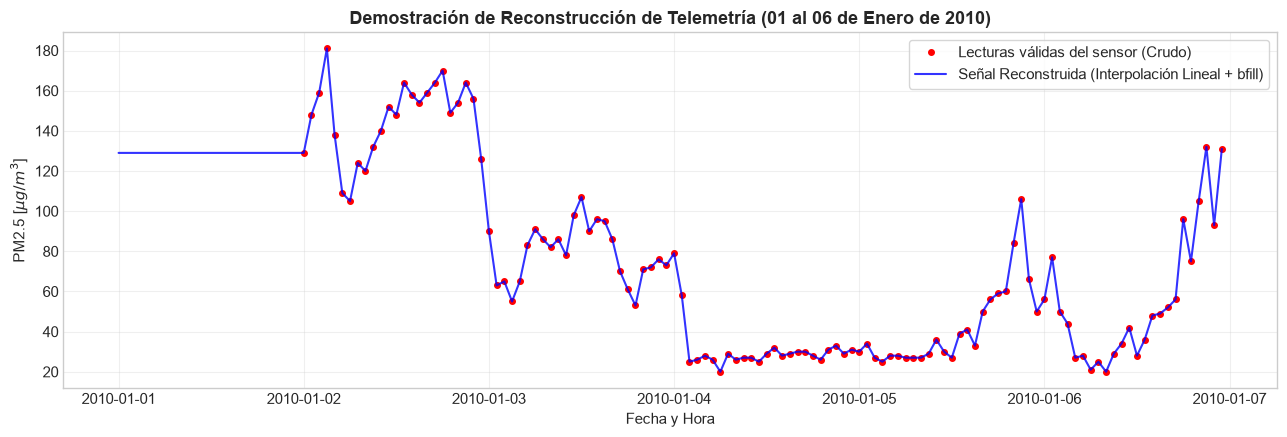

In [6]:
# 2.3 Comparación gráfica de señal cruda vs señal interpolada (Ventana de 5 días en enero 2010)
ventana_demo = slice('2010-01-01', '2010-01-06')

plt.figure(figsize=(13, 4.5))
plt.plot(df.loc[ventana_demo].index, df.loc[ventana_demo, 'pm2.5'], 'ro', markersize=4, label='Lecturas válidas del sensor (Crudo)')
plt.plot(df_limpio.loc[ventana_demo].index, df_limpio.loc[ventana_demo, 'pm2.5_limpio'], 'b-', alpha=0.8, lw=1.5, label='Señal Reconstruida (Interpolación Lineal + bfill)')
plt.title('Demostración de Reconstrucción de Telemetría (01 al 06 de Enero de 2010)', fontweight='bold')
plt.xlabel('Fecha y Hora')
plt.ylabel('PM2.5 [$\\mu g / m^3$]')
plt.legend(frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# 3.1 Construcción de máscaras booleanas compuestas
condicion_smog_critico = (df_limpio['pm2.5_limpio'] > 150.0)
condicion_bajo_cero = (df_limpio['TEMP'] < 0.0)
condicion_viento_calmo = (df_limpio['Iws'] < 2.0)

# Máscara compuesta: Smog Severo Y Temperatura Bajo Cero
mascara_inversion_termica = condicion_smog_critico & condicion_bajo_cero

# 3.2 Aplicación de la máscara (Slicing Condicional)
df_critico_global = df_limpio[mascara_inversion_termica]

print(f"Total de horas registradas en 5 años:          {len(df_limpio):,} hrs")
print(f"Horas bajo condición crítica (PM2.5 > 150 & T < 0): {len(df_critico_global):,} hrs ({len(df_critico_global)/len(df_limpio)*100:.2f}%)")

# 3.3 Slicing Temporal: Aislamos el mes de Enero de 2013
df_enero2013 = df_limpio.loc['2013-01-01':'2013-01-31'].copy()
df_enero2013_critico = df_enero2013[(df_enero2013['pm2.5_limpio'] > 150.0) & (df_enero2013['TEMP'] < 0.0)]

print(f"\nEn Enero 2013:")
print(f"- Horas totales del mes: {len(df_enero2013)} hrs")
print(f"- Horas bajo emergencia crítica simultánea: {len(df_enero2013_critico)} hrs ({len(df_enero2013_critico)/len(df_enero2013)*100:.2f}%)")
display(df_enero2013_critico[['pm2.5_limpio', 'TEMP', 'PRES', 'Iws', 'cbwd']].head(6))

Total de horas registradas en 5 años:          43,824 hrs
Horas bajo condición crítica (PM2.5 > 150 & T < 0): 2,301 hrs (5.25%)

En Enero 2013:
- Horas totales del mes: 744 hrs
- Horas bajo emergencia crítica simultánea: 341 hrs (45.83%)


,pm2.5_limpio,TEMP,PRES,Iws,cbwd
datetime,,,,,
2013-01-04 21:00:00,186.0,-12.0,1029.0,1.79,cv
2013-01-04 22:00:00,205.0,-13.0,1029.0,2.68,cv
2013-01-04 23:00:00,204.0,-15.0,1029.0,1.79,NW
2013-01-05 00:00:00,198.0,-14.0,1029.0,2.68,NW
2013-01-05 01:00:00,176.0,-14.0,1028.0,0.89,cv
2013-01-06 17:00:00,193.0,-1.0,1025.0,9.39,SE


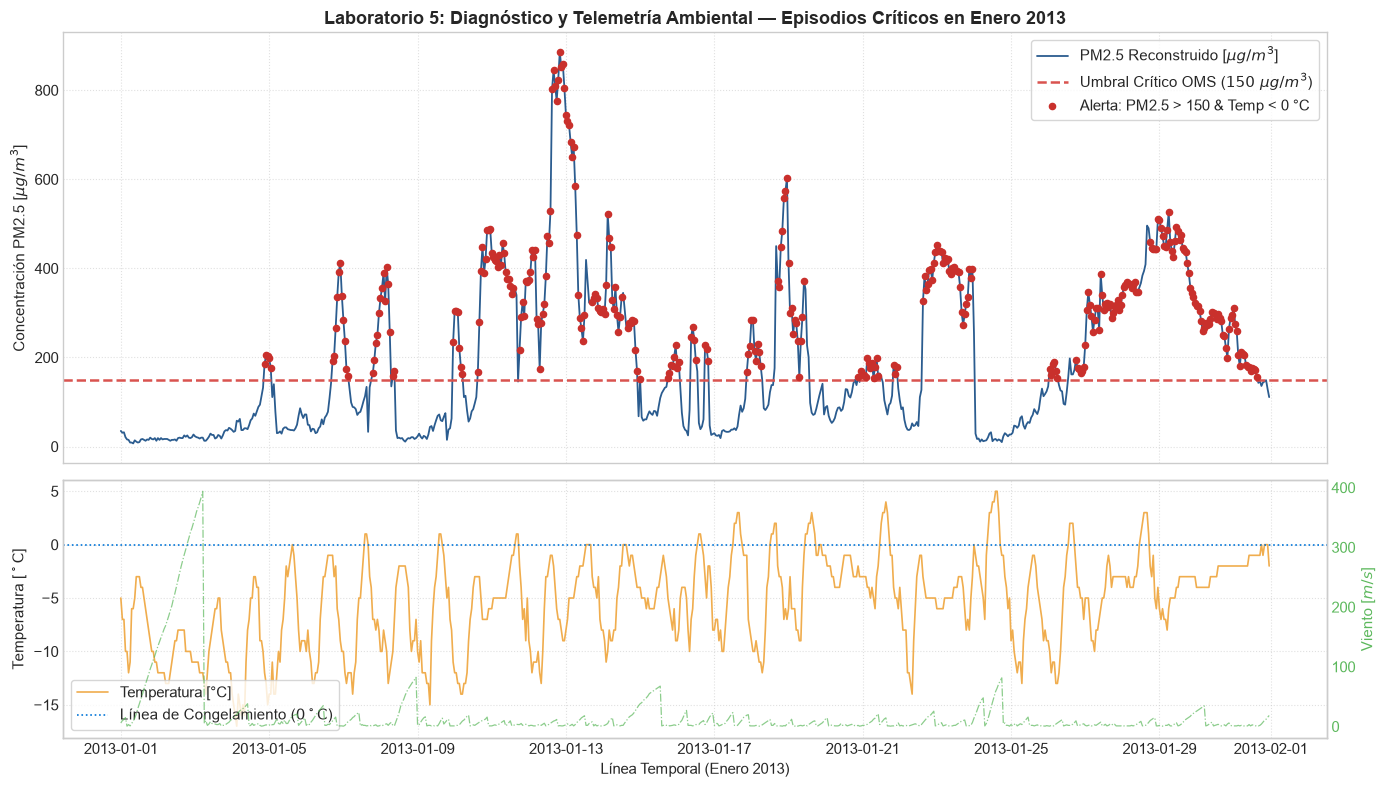

In [8]:
# 4.1 Visualización técnica de la serie temporal filtrada
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1.2]})

# Panel 1: Material Particulado PM2.5
ax1.plot(df_enero2013.index, df_enero2013['pm2.5_limpio'], color='#2b5c8f', lw=1.3, label='PM2.5 Reconstruido [$\\mu g/m^3$]')
ax1.axhline(150, color='#d9534f', linestyle='--', lw=1.8, label='Umbral Crítico OMS ($150\\ \\mu g/m^3$)')

# Resaltado de puntos críticos bajo cero
ax1.scatter(df_enero2013_critico.index, df_enero2013_critico['pm2.5_limpio'], color='#c9302c', s=20, zorder=5, label='Alerta: PM2.5 > 150 & Temp < 0 °C')

ax1.set_title('Laboratorio 5: Diagnóstico y Telemetría Ambiental — Episodios Críticos en Enero 2013', fontsize=13, fontweight='bold')
ax1.set_ylabel('Concentración PM2.5 [$\\mu g/m^3$]', fontsize=11)
ax1.legend(loc='upper right', frameon=True)
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel 2: Variables Meteorológicas (Temperatura y Viento)
ax2.plot(df_enero2013.index, df_enero2013['TEMP'], color='#f0ad4e', lw=1.2, label='Temperatura [°C]')
ax2.axhline(0, color='#0275d8', linestyle=':', lw=1.2, label='Línea de Congelamiento ($0^\\circ\\text{C}$)')

# Segundo eje Y para velocidad del viento acumulada
ax2_twin = ax2.twinx()
ax2_twin.plot(df_enero2013.index, df_enero2013['Iws'], color='#5cb85c', lw=0.9, linestyle='-.', alpha=0.7, label='Velocidad Viento ($I_{ws}$) [m/s]')
ax2_twin.set_ylabel('Viento [$m/s$]', color='#5cb85c', fontsize=11)
ax2_twin.tick_params(axis='y', labelcolor='#5cb85c')
ax2_twin.grid(False)

ax2.set_ylabel('Temperatura [$^\\circ\\text{C}$]', fontsize=11)
ax2.set_xlabel('Línea Temporal (Enero 2013)', fontsize=11)
ax2.legend(loc='lower left', frameon=True)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()